# Practice Solutions

:::{admonition} Reference solutions
:class: note
Worked solutions for every exercise in [1.8-statistical-foundations-and-ml-practice-exercises.ipynb](1.8-statistical-foundations-and-ml-practice-exercises.ipynb).
:::

## Exercise 1: Explore

Build a DataFrame of 60 stations with `elevation_m` uniform on [200, 3500] and `temp_celsius = 15 - 6.5 * elevation_m/1000 + noise` (noise standard deviation 1.5 °C, seeded). Make a seaborn regression plot of temperature against elevation and print `describe()`.

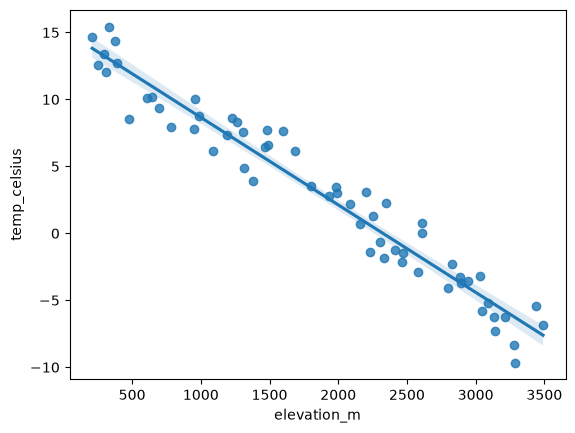

       elevation_m  temp_celsius
count        60.00         60.00
mean       1867.55          2.99
std         987.31          6.63
min         209.04         -9.66
25%        1065.20         -2.44
50%        1990.39          3.03
75%        2655.25          8.03
max        3490.79         15.43


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
rng = np.random.default_rng(0)
elev = rng.uniform(200, 3500, 60)
temp = 15 - 6.5 * (elev / 1000) + rng.normal(0, 1.5, 60)
df = pd.DataFrame({"elevation_m": elev, "temp_celsius": temp})
sns.regplot(data=df, x="elevation_m", y="temp_celsius")
plt.show()
print(df.describe().round(2))

## Exercise 2: Correlation

Print the Pearson correlation matrix of the DataFrame and identify the sign of the temperature–elevation correlation.

In [ ]:
print(df.corr().round(3))   # temperature vs elevation is strongly negative (the lapse rate)

              elevation_m  temp_celsius
elevation_m         1.000        -0.973
temp_celsius       -0.973         1.000


## Exercise 3: Fit a linear regression

Fit `LinearRegression` with `X = df[["elevation_m"]]` and `y = df["temp_celsius"]`. Print the recovered lapse rate in °C km⁻¹ and the intercept.

In [ ]:
from sklearn.linear_model import LinearRegression
X = df[["elevation_m"]]; y = df["temp_celsius"]
m = LinearRegression().fit(X, y)
print(round(m.coef_[0] * 1000, 2), "°C km^-1")
print(round(m.intercept_, 2), "°C")

-6.53 °C km^-1
15.18 °C


## Exercise 4: Honest evaluation

Split the data (test size 0.3, fixed random state), fit on the training set, and report the test RMSE and R^2.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error, r2_score
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0)
m = LinearRegression().fit(Xtr, ytr)
p = m.predict(Xte)
print("RMSE:", round(root_mean_squared_error(yte, p), 3))
print("R^2: ", round(r2_score(yte, p), 3))

RMSE: 1.35
R^2:  0.962


## Exercise 5: A pipeline with scaling

Build a `Pipeline` of `StandardScaler` followed by `LinearRegression`, fit it on the training set, and print its test R^2 (via `.score`).

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
pipe = make_pipeline(StandardScaler(), LinearRegression()).fit(Xtr, ytr)
print(round(pipe.score(Xte, yte), 3))

0.962


## Exercise 6: Demonstrate overfitting

Generate 20 noisy points on the lapse rate in kilometres: `x_km = np.linspace(0.2, 3.5, 20)` and `temp_celsius = 15 - 6.5 * x_km + noise`, with noise of standard deviation 2.0 °C from `np.random.default_rng(2)`. Hold out 40 % of the points (`test_size=0.4`, `random_state=0`).

Fit a degree-8 polynomial pipeline (`PolynomialFeatures(degree=8)` followed by `LinearRegression`) on the training part and compare its R^2 on the training data with its R^2 on the test data. Then fit a plain `LinearRegression` and compare its test R^2. Comment on the gap: a degree-8 polynomial has nine parameters and only 12 training points, so it can follow the noise.

In [ ]:
from sklearn.preprocessing import PolynomialFeatures

rng = np.random.default_rng(2)
x_km = np.linspace(0.2, 3.5, 20)
temp_celsius = 15 - 6.5 * x_km + rng.normal(0, 2.0, 20)
Xk_tr, Xk_te, yk_tr, yk_te = train_test_split(
    x_km.reshape(-1, 1), temp_celsius, test_size=0.4, random_state=0
)

over = make_pipeline(PolynomialFeatures(degree=8), LinearRegression()).fit(Xk_tr, yk_tr)
line = LinearRegression().fit(Xk_tr, yk_tr)
print("degree-8 train R^2:", round(over.score(Xk_tr, yk_tr), 3))   # 0.942
print("degree-8 test  R^2:", round(over.score(Xk_te, yk_te), 1))   # about -119
print("linear   test  R^2:", round(line.score(Xk_te, yk_te), 3))   # 0.96

# Nine parameters and 12 training points: the polynomial bends through the noise, so its
# training score is high while its predictions at new elevations are far worse than a
# constant. The straight line, which has the right physical form, loses almost nothing.

## Exercise 7 (optional): Cross-validation

Cross-validation appears in the lecture's going-deeper box. Use `cross_val_score` with 5 folds to estimate the R^2 of a plain `LinearRegression` on the full dataset, and print the mean and standard deviation across folds.

In [ ]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(LinearRegression(), X, y, cv=5, scoring="r2")
print(round(scores.mean(), 3), round(scores.std(), 3))

0.938 0.013
